In [ ]:
# Residency Day 2 - Project Deliverable 3
# Classification, Clustering, and Pattern Mining
# Dataset: California Housing (same dataset as Deliverable 2).
# Classification target: 0 = at/below median house value; 1 = above median.
# Apriori note: the source data has no real transactions. We create category
# baskets from housing attributes, so rules describe co-occurrence in housing data.

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay, roc_curve, roc_auc_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
print("Libraries imported.")

Libraries imported.


In [ ]:
# STEP 1: LOAD AND INSPECT THE DATASET

housing = fetch_california_housing(as_frame=True)
df = housing.frame.rename(columns={"MedHouseVal": "median_house_value"}).copy()

print("Dataset shape:", df.shape)
display(df.head())
df.info()
display(df.describe().T)

Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,median_house_value
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   MedInc              20640 non-null  float64
 1   HouseAge            20640 non-null  float64
 2   AveRooms            20640 non-null  float64
 3   AveBedrms           20640 non-null  float64
 4   Population          20640 non-null  float64
 5   AveOccup            20640 non-null  float64
 6   Latitude            20640 non-null  float64
 7   Longitude           20640 non-null  float64
 8   median_house_value  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
median_house_value,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


In [ ]:
# STEP 2: CHECK AND CLEAN DATA

print("Missing values:")
display(df.isnull().sum().to_frame("missing_values"))
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.replace([np.inf, -np.inf], np.nan).dropna().copy()
print("Shape after cleaning:", df.shape)

Missing values:


,missing_values
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
median_house_value,0


Duplicate rows: 0
Shape after cleaning: (20640, 9)


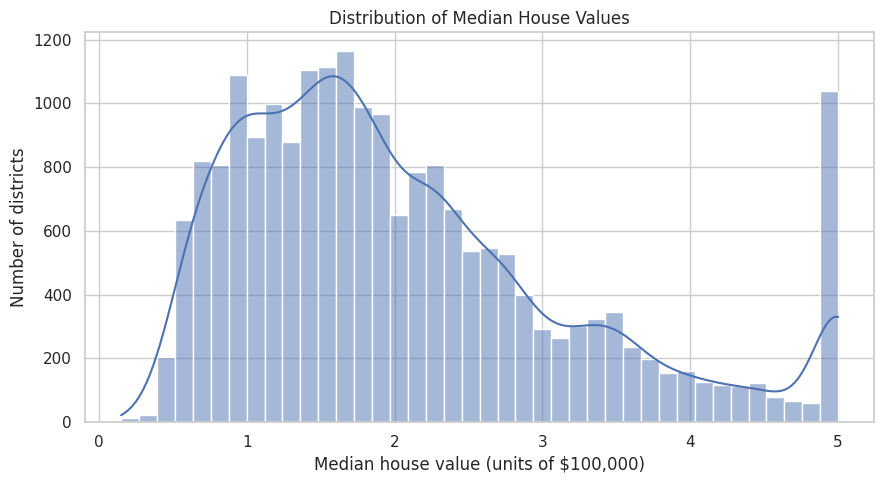

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: median_house_value, dtype: float64


In [ ]:
# STEP 3: EXPLORE THE TARGET VARIABLE

plt.figure(figsize=(9, 5))
sns.histplot(df["median_house_value"], bins=40, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median house value (units of $100,000)")
plt.ylabel("Number of districts")
plt.tight_layout()
plt.show()
print(df["median_house_value"].describe())

In [ ]:
# STEP 4: FEATURE ENGINEERING
# Add ratios based on the original housing attributes.

df["rooms_per_household"] = df["AveRooms"]
df["bedrooms_per_room"] = df["AveBedrms"] / df["AveRooms"].replace(0, np.nan)
df["population_per_household"] = df["Population"] / df["AveOccup"].replace(0, np.nan)
df["income_per_room"] = df["MedInc"] / df["AveRooms"].replace(0, np.nan)
df = df.replace([np.inf, -np.inf], np.nan).dropna().copy()

feature_columns = [
    "MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population",
    "AveOccup", "Latitude", "Longitude", "rooms_per_household",
    "bedrooms_per_room", "population_per_household", "income_per_room"
]
print("Rows:", len(df), "| Predictor features:", len(feature_columns))
display(df[feature_columns].head())

Rows: 20640 | Predictor features: 12


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,rooms_per_household,bedrooms_per_room,population_per_household,income_per_room
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,6.984127,0.146591,126.0,1.192017
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,6.238137,0.155797,1138.0,1.330750
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,8.288136,0.129516,177.0,0.875637
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,5.817352,0.184458,219.0,0.970046
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,6.281853,0.172096,259.0,0.612272


Median threshold: 1.797
Threshold in dollars: approximately $ 179700


,records
house_value_class,
0,10323
1,10317


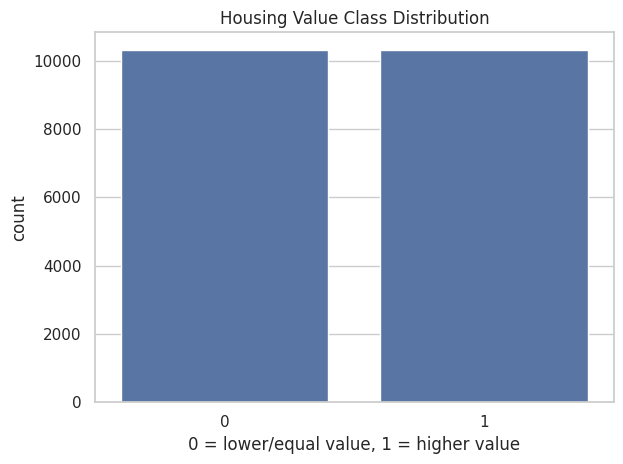

In [ ]:
# STEP 5: CREATE THE CLASSIFICATION TARGET
# The continuous house value is converted into two classes using its median.
# Class 0: value is at or below the median.
# Class 1: value is above the median.

classification_threshold = df["median_house_value"].median()
df["house_value_class"] = (
    df["median_house_value"] > classification_threshold
).astype(int)

print("Median threshold:", classification_threshold)
print("Threshold in dollars: approximately $", round(classification_threshold * 100000))
display(df["house_value_class"].value_counts().to_frame("records"))

sns.countplot(data=df, x="house_value_class")
plt.title("Housing Value Class Distribution")
plt.xlabel("0 = lower/equal value, 1 = higher value")
plt.tight_layout()
plt.show()

In [ ]:
# STEP 6: SPLIT DATA FOR CLASSIFICATION
# The continuous target is excluded from predictors to prevent target leakage.
# Stratification preserves the class balance in train and test partitions.

X = df[feature_columns]
y = df["house_value_class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 16512
Testing records: 4128


In [ ]:
# STEP 7: TRAIN THE TWO REQUIRED CLASSIFICATION MODELS

decision_tree = DecisionTreeClassifier(
    max_depth=8, min_samples_split=10, random_state=RANDOM_STATE
)
decision_tree.fit(X_train, y_train)
dt_pred = decision_tree.predict(X_test)

random_forest = RandomForestClassifier(
    n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
)
random_forest.fit(X_train, y_train)
rf_pred = random_forest.predict(X_test)

print("DECISION TREE")
print(classification_report(y_test, dt_pred))
print("RANDOM FOREST")
print(classification_report(y_test, rf_pred))

DECISION TREE
              precision    recall  f1-score   support

           0       0.86      0.85      0.85      2065
           1       0.85      0.86      0.85      2063

    accuracy                           0.85      4128
   macro avg       0.85      0.85      0.85      4128
weighted avg       0.85      0.85      0.85      4128

RANDOM FOREST
              precision    recall  f1-score   support

           0       0.88      0.90      0.89      2065
           1       0.90      0.87      0.88      2063

    accuracy                           0.89      4128
   macro avg       0.89      0.89      0.89      4128
weighted avg       0.89      0.89      0.89      4128



In [ ]:
# STEP 8: COMPARE CLASSIFICATION METRICS

def classification_metrics(name, actual, predicted, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1-score": f1_score(actual, predicted, zero_division=0),
        "ROC-AUC": roc_auc_score(actual, probabilities)
    }

dt_prob = decision_tree.predict_proba(X_test)[:, 1]
rf_prob = random_forest.predict_proba(X_test)[:, 1]

classification_results = pd.DataFrame([
    classification_metrics("Decision Tree", y_test, dt_pred, dt_prob),
    classification_metrics("Random Forest", y_test, rf_pred, rf_prob)
])
display(classification_results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.8530,0.8507,0.856,0.8533,0.9092
1,Random Forest,0.8861,0.8957,0.874,0.8847,0.9559


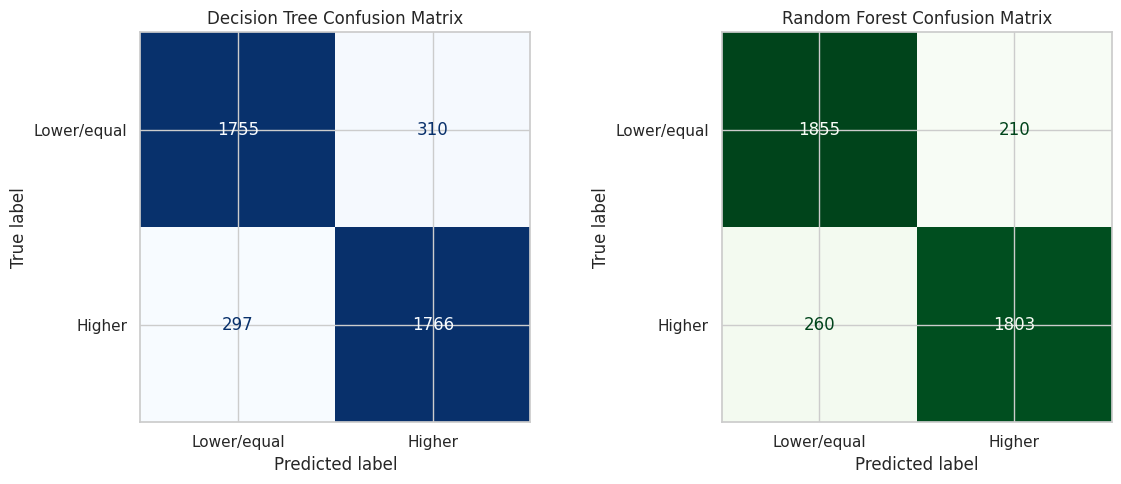

In [ ]:
# STEP 9: CONFUSION MATRICES

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, dt_pred, display_labels=["Lower/equal", "Higher"],
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Decision Tree Confusion Matrix")
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred, display_labels=["Lower/equal", "Higher"],
    cmap="Greens", ax=axes[1], colorbar=False
)
axes[1].set_title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

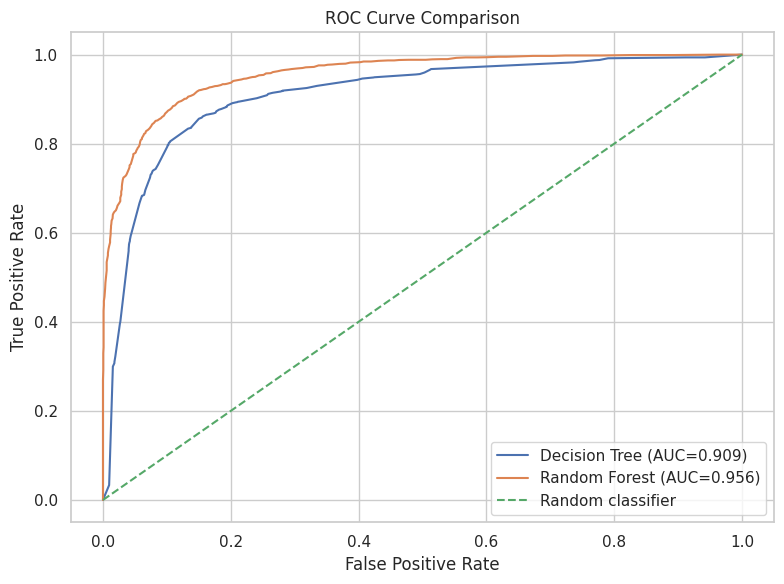

In [ ]:
# STEP 10: ROC CURVE AND AUC

dt_fpr, dt_tpr, _ = roc_curve(y_test, dt_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
dt_auc = roc_auc_score(y_test, dt_prob)
rf_auc = roc_auc_score(y_test, rf_prob)

plt.figure(figsize=(8, 6))
plt.plot(dt_fpr, dt_tpr, label=f"Decision Tree (AUC={dt_auc:.3f})")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC={rf_auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# STEP 11: HYPERPARAMETER TUNING FOR RANDOM FOREST
# GridSearchCV uses 3-fold cross-validation and selects the best F1-score.

parameter_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    parameter_grid, scoring="f1", cv=3, n_jobs=-1, verbose=1
)
grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_
tuned_pred = best_rf.predict(X_test)
tuned_prob = best_rf.predict_proba(X_test)[:, 1]

print("Best parameters:", grid_search.best_params_)
print("Best CV F1-score:", round(grid_search.best_score_, 4))
print(classification_report(y_test, tuned_pred))

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best parameters: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Best CV F1-score: 0.8738
              precision    recall  f1-score   support

           0       0.88      0.89      0.88      2065
           1       0.89      0.88      0.88      2063

    accuracy                           0.88      4128
   macro avg       0.88      0.88      0.88      4128
weighted avg       0.88      0.88      0.88      4128



,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.8530,0.8507,0.8560,0.8533,0.9092
1,Random Forest,0.8861,0.8957,0.8740,0.8847,0.9559
2,Tuned Random Forest,0.8840,0.8901,0.8759,0.8830,0.9553


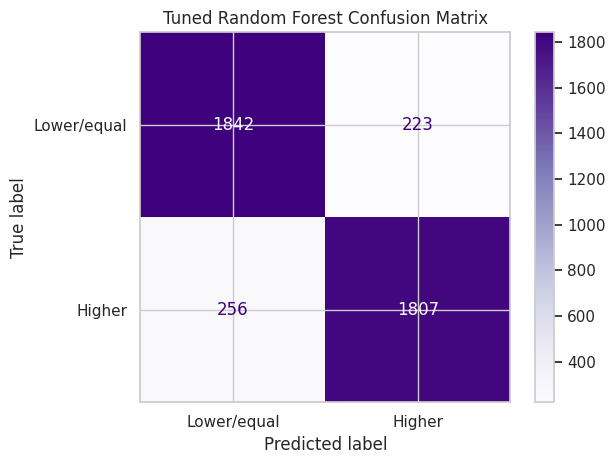

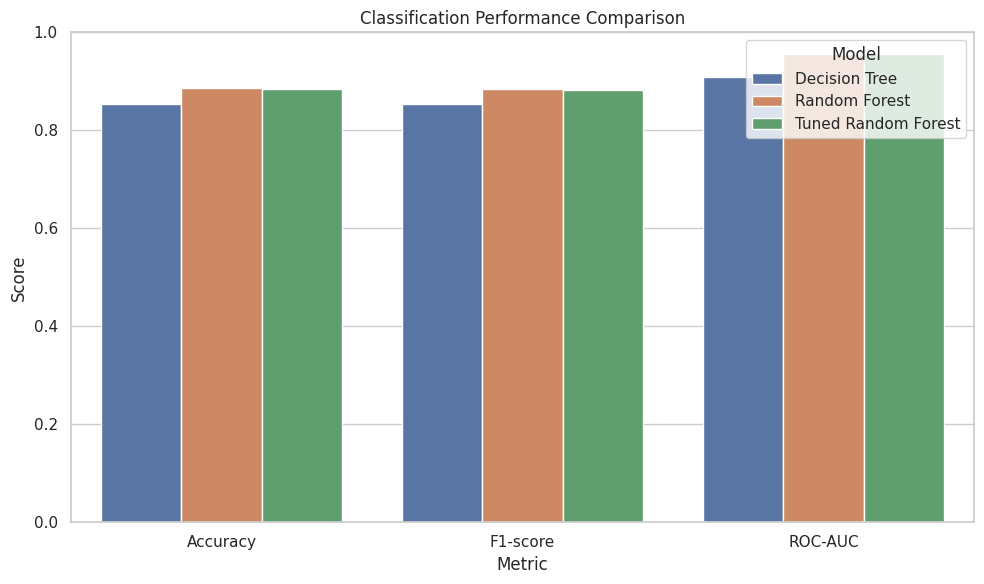

In [13]:
# STEP 12: EVALUATE AND VISUALIZE THE TUNED MODEL

tuned_row = classification_metrics(
    "Tuned Random Forest", y_test, tuned_pred, tuned_prob
)
comparison = pd.concat([
    classification_results,
    pd.DataFrame([tuned_row])
], ignore_index=True)
display(comparison.round(4))

ConfusionMatrixDisplay.from_predictions(
    y_test, tuned_pred, display_labels=["Lower/equal", "Higher"], cmap="Purples"
)
plt.title("Tuned Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

comparison_plot = comparison.melt(
    id_vars="Model",
    value_vars=["Accuracy", "F1-score", "ROC-AUC"],
    var_name="Metric", value_name="Score"
)
plt.figure(figsize=(10, 6))
sns.barplot(data=comparison_plot, x="Metric", y="Score", hue="Model")
plt.ylim(0, 1)
plt.title("Classification Performance Comparison")
plt.tight_layout()
plt.show()

,Feature,Importance
11,income_per_room,0.2156
0,MedInc,0.1690
6,Latitude,0.1118
7,Longitude,0.1093
5,AveOccup,0.1077
9,bedrooms_per_room,0.0654
1,HouseAge,0.0457
8,rooms_per_household,0.0387
2,AveRooms,0.0380
3,AveBedrms,0.0354


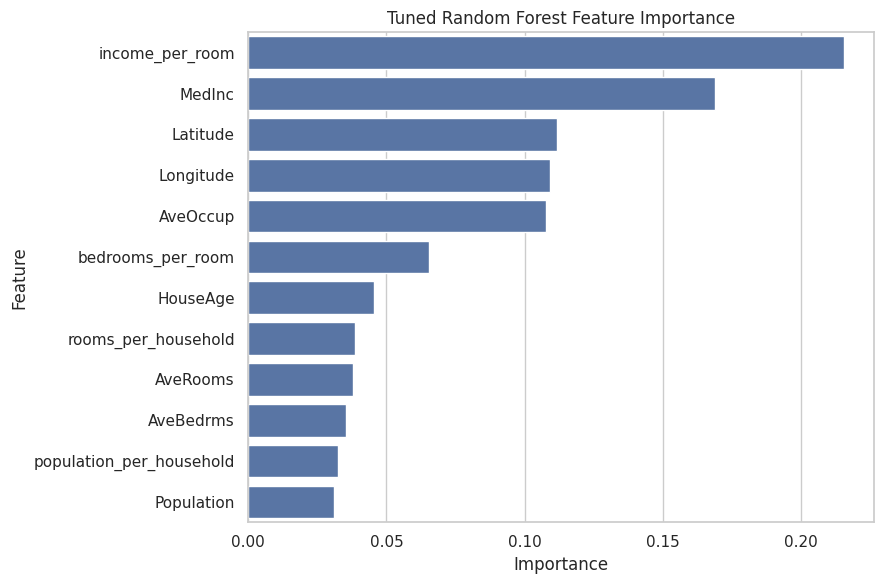

In [14]:
# STEP 13: RANDOM FOREST FEATURE IMPORTANCE

importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": best_rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance.round(4))
plt.figure(figsize=(9, 6))
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Tuned Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [15]:
# STEP 14: PREPARE FEATURES FOR K-MEANS CLUSTERING
# Clustering is unsupervised. Do not include the target class or house value.
# Standardize features because K-Means uses distances.

cluster_scaler = StandardScaler()
cluster_scaled = cluster_scaler.fit_transform(df[feature_columns])
print("Clustering matrix shape:", cluster_scaled.shape)

Clustering matrix shape: (20640, 12)


,k,Inertia,Silhouette
0,2,48289.4800,0.9610
1,3,43009.6416,0.1880
2,4,34000.9773,0.2269
3,5,29510.8966,0.2334
4,6,25081.7223,0.2454


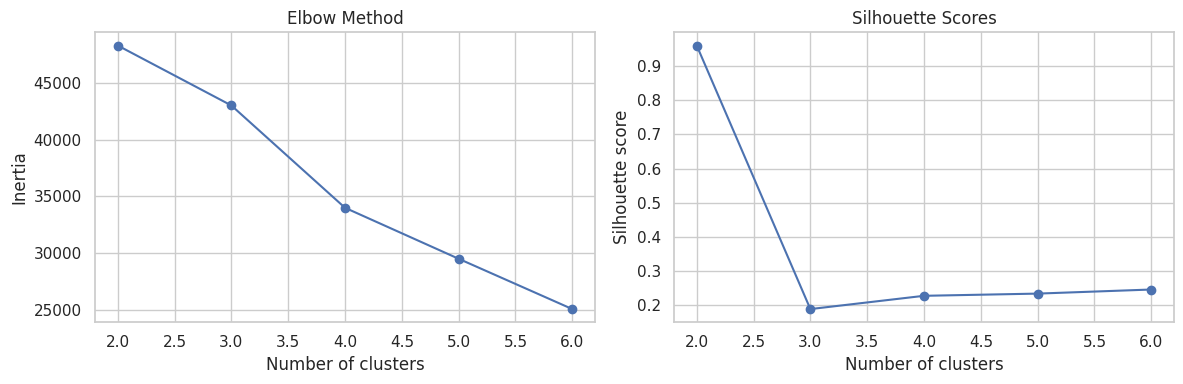

In [16]:
# STEP 15: SELECT THE NUMBER OF CLUSTERS
# Compare inertia and silhouette scores for k values from 2 through 6.
# Silhouette is calculated on a sample to keep execution time manageable.

rng = np.random.RandomState(RANDOM_STATE)
sample_size = min(5000, len(cluster_scaled))
sample_idx = rng.choice(len(cluster_scaled), size=sample_size, replace=False)
cluster_sample = cluster_scaled[sample_idx]

k_values = range(2, 7)
inertias, silhouettes = [], []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    sample_labels = km.fit_predict(cluster_sample)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(cluster_sample, sample_labels))

cluster_selection = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette": silhouettes
})
display(cluster_selection.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o")
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

In [17]:
# STEP 16: FIT K-MEANS AND SUMMARIZE CLUSTERS
# Choose the tested k with the highest sample silhouette score.

best_k = int(cluster_selection.loc[
    cluster_selection["Silhouette"].idxmax(), "k"
])
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
df["cluster"] = kmeans.fit_predict(cluster_scaled)

full_silhouette = silhouette_score(
    cluster_scaled, df["cluster"],
    sample_size=min(5000, len(df)), random_state=RANDOM_STATE
)
print("Selected k:", best_k)
print("Sampled full-data silhouette score:", round(full_silhouette, 4))
display(df["cluster"].value_counts().sort_index().to_frame("records"))

cluster_profile = df.groupby("cluster")[[
    "MedInc", "HouseAge", "AveRooms", "AveBedrms",
    "Population", "AveOccup", "Latitude", "Longitude",
    "median_house_value"
]].mean()
display(cluster_profile.round(3))

Selected k: 2
Sampled full-data silhouette score: 0.2395


,records
cluster,
0,8890
1,11750


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,median_house_value
cluster,,,,,,,,,
0,3.787,28.811,5.738,1.129,1264.448,2.893,37.903,-121.663,1.953
1,3.934,28.510,5.195,1.072,1547.311,3.205,33.913,-117.986,2.156


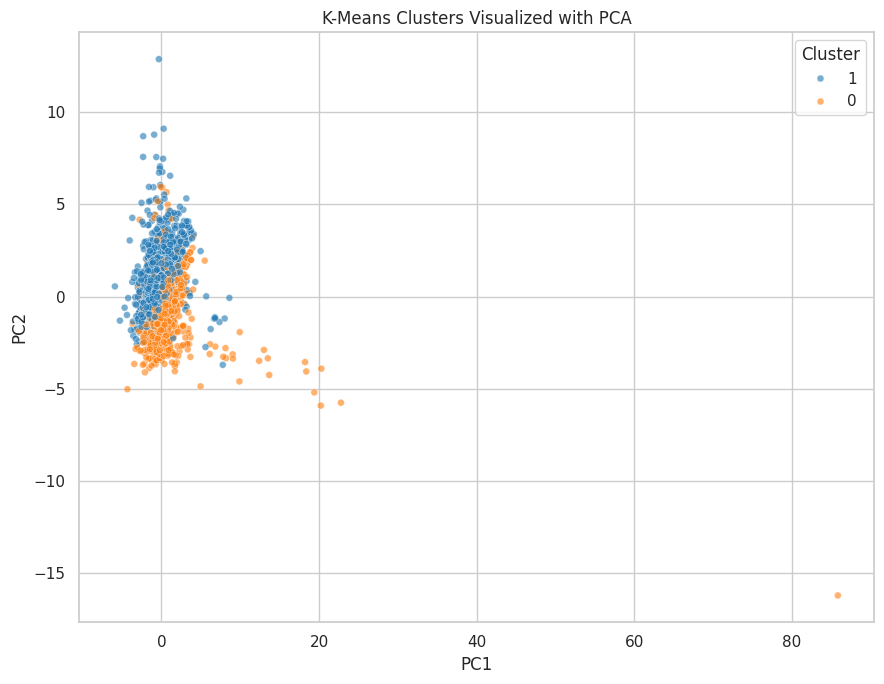

Variance explained by two PCA components: 0.453


In [18]:
# STEP 17: VISUALIZE CLUSTERS USING PCA
# PCA projects all standardized clustering features into two dimensions.
# The K-Means model itself uses the full standardized feature set.

pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_values = pca.fit_transform(cluster_scaled)
pca_df = pd.DataFrame({
    "PC1": pca_values[:, 0],
    "PC2": pca_values[:, 1],
    "Cluster": df["cluster"].astype(str).values
})
pca_sample = pca_df.sample(
    n=min(5000, len(pca_df)), random_state=RANDOM_STATE
)

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=pca_sample, x="PC1", y="PC2",
    hue="Cluster", palette="tab10", alpha=0.6, s=25
)
plt.title("K-Means Clusters Visualized with PCA")
plt.tight_layout()
plt.show()
print("Variance explained by two PCA components:",
      round(pca.explained_variance_ratio_.sum(), 4))

In [19]:
# STEP 18: PREPARE DERIVED CATEGORY BASKETS FOR APRIORI
# The housing data does not contain real transactions.
# Each district is represented by categorical items derived from its features.
# Therefore, Apriori findings are housing-category co-occurrences, not purchases.

basket_source = df[
    ["MedInc", "HouseAge", "AveRooms", "median_house_value"]
].copy()

basket = pd.DataFrame(index=basket_source.index)
basket["income_band"] = pd.qcut(
    basket_source["MedInc"], q=3,
    labels=["income_low", "income_medium", "income_high"],
    duplicates="drop"
).astype(str)
basket["age_band"] = pd.qcut(
    basket_source["HouseAge"], q=3,
    labels=["age_low", "age_medium", "age_high"],
    duplicates="drop"
).astype(str)
basket["rooms_band"] = pd.qcut(
    basket_source["AveRooms"], q=3,
    labels=["rooms_low", "rooms_medium", "rooms_high"],
    duplicates="drop"
).astype(str)
basket["value_band"] = pd.qcut(
    basket_source["median_house_value"], q=3,
    labels=["value_low", "value_medium", "value_high"],
    duplicates="drop"
).astype(str)

display(basket.head())

,income_band,age_band,rooms_band,value_band
0,income_high,age_high,rooms_high,value_high
1,income_high,age_low,rooms_high,value_high
2,income_high,age_high,rooms_high,value_high
3,income_high,age_high,rooms_high,value_high
4,income_medium,age_high,rooms_high,value_high


In [20]:
# STEP 19: INSTALL APRIORI PACKAGE AND ENCODE TRANSACTIONS

%pip -q install mlxtend

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

transactions = basket.astype(str).values.tolist()
encoder = TransactionEncoder()
encoded = encoder.fit(transactions).transform(transactions)
transaction_matrix = pd.DataFrame(
    encoded, columns=encoder.columns_, index=basket.index
)

print("Transaction matrix shape:", transaction_matrix.shape)
display(transaction_matrix.head())

Transaction matrix shape: (20640, 12)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,age_high,age_low,age_medium,income_high,income_low,income_medium,rooms_high,rooms_low,rooms_medium,value_high,value_low,value_medium
0,True,False,False,True,False,False,True,False,False,True,False,False
1,False,True,False,True,False,False,True,False,False,True,False,False
2,True,False,False,True,False,False,True,False,False,True,False,False
3,True,False,False,True,False,False,True,False,False,True,False,False
4,True,False,False,False,False,True,True,False,False,True,False,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [21]:
# STEP 20: FIND FREQUENT ITEMSETS USING APRIORI
# An itemset must appear in at least 5% of the observations.

frequent_itemsets_raw = apriori(
    transaction_matrix, min_support=0.05, use_colnames=True
)
print("Frequent itemsets found:", len(frequent_itemsets_raw))

frequent_itemsets = frequent_itemsets_raw.copy()
frequent_itemsets["items"] = frequent_itemsets["itemsets"].apply(
    lambda values: ", ".join(sorted(values))
)
display(
    frequent_itemsets[["support", "items"]]
    .sort_values("support", ascending=False)
    .head(20)
)

Frequent itemsets found: 88


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,support,items
2,0.346802,age_medium
1,0.345833,age_low
10,0.333527,value_low
5,0.333382,income_medium
6,0.333333,rooms_high
7,0.333333,rooms_low
8,0.333333,rooms_medium
4,0.333333,income_low
9,0.333333,value_high
3,0.333285,income_high


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents_text,consequents_text,support,confidence,lift
0,"age_medium, rooms_high, value_high",income_high,0.055475,0.942387,2.827571
1,"age_low, rooms_high, value_high",income_high,0.065649,0.931271,2.794221
2,"age_low, value_high","income_high, rooms_high",0.065649,0.634958,2.782490
3,"rooms_high, value_high",income_high,0.159884,0.927227,2.782085
4,income_high,"rooms_high, value_high",0.159884,0.479721,2.782085
5,"age_low, income_high","rooms_high, value_high",0.065649,0.478629,2.775755
6,"rooms_high, value_high","age_low, income_high",0.065649,0.380725,2.775755
7,"age_medium, income_high","rooms_high, value_high",0.055475,0.478479,2.774882
8,"rooms_high, value_high","age_medium, income_high",0.055475,0.321720,2.774882
9,"rooms_low, value_low",income_low,0.110271,0.874712,2.624135


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

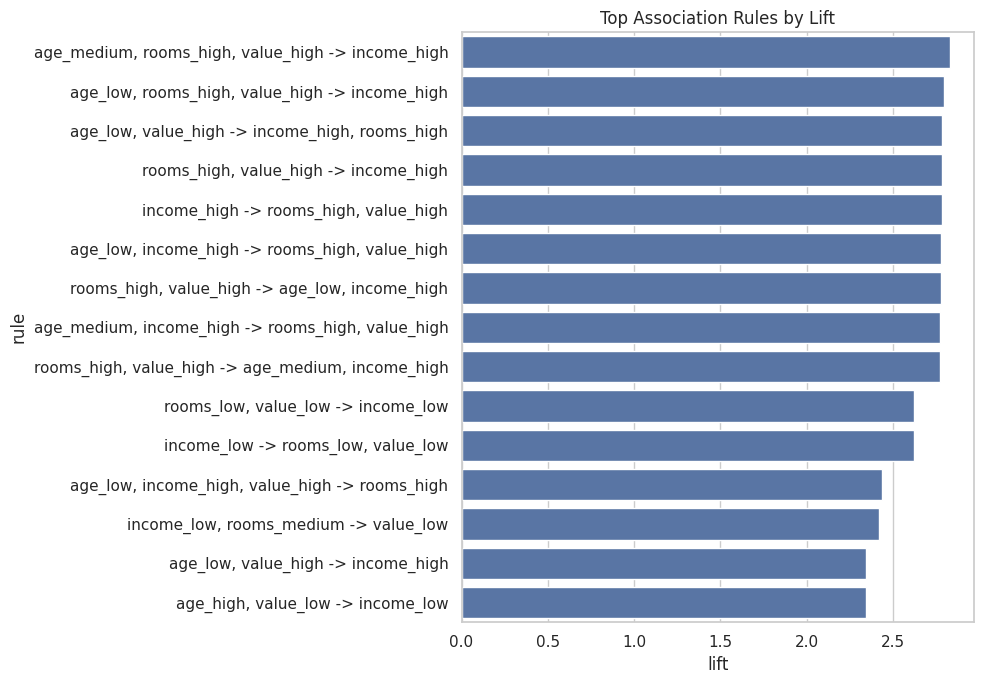

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [22]:
# STEP 21: GENERATE AND INTERPRET ASSOCIATION RULES
# Confidence is the conditional frequency of the consequent.
# Lift above 1 indicates positive association relative to independence.

if len(frequent_itemsets_raw) >= 2:
    rules = association_rules(
        frequent_itemsets_raw,
        metric="confidence",
        min_threshold=0.30
    )
else:
    rules = pd.DataFrame()

if not rules.empty:
    rules["antecedents_text"] = rules["antecedents"].apply(
        lambda values: ", ".join(sorted(values))
    )
    rules["consequents_text"] = rules["consequents"].apply(
        lambda values: ", ".join(sorted(values))
    )
    rules = rules.sort_values(
        ["lift", "confidence"], ascending=False
    ).reset_index(drop=True)

    display(rules[[
        "antecedents_text", "consequents_text",
        "support", "confidence", "lift"
    ]].head(20))

    top_rules = rules.head(15).copy()
    top_rules["rule"] = (
        top_rules["antecedents_text"] + " -> " +
        top_rules["consequents_text"]
    )
    plt.figure(figsize=(10, 7))
    sns.barplot(data=top_rules, x="lift", y="rule")
    plt.title("Top Association Rules by Lift")
    plt.tight_layout()
    plt.show()
else:
    print("No rules met the selected support and confidence thresholds.")